# 01 · Main aggregation and independent baselines
**Measured scope:** six checkpoints × ETTh1/ETTh2/ETTm1/ETTm2/Appliances/BeijingWeather ×
horizons 96/192/336/720 × three seeds = 432 cells. Relative errors divide each cell by its
frozen backbone. Geometric means give equal weight to cells, not datasets' raw loss scales.
Oracle uses unavailable test labels and is never a deployed method. These are the revised
max_delta=0.3, 80-candidate, Retrieval-demo top-10 measurements.


In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'artifacts/manifest.json').exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ttc4ts.results import (checked_path, load_snapshot, geometric, summarize,
    main_summary, lw_budget_summary, uncertainty_summary, MODELS, MODEL_LABELS, METHODS, METHOD_LABELS)
%matplotlib inline
plt.rcParams.update({'figure.dpi': 115, 'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
pd.set_option('display.max_rows', 60)
pd.set_option('display.float_format', lambda x: f'{x:.5f}')
print('Offline mode: numerical snapshots are verified against the released SHA-256 manifest.')


Offline mode: numerical snapshots are verified against the released SHA-256 manifest.


In [2]:
raw = load_snapshot('main')
headline = raw[raw.method.isin(METHODS)].copy()
assert len(headline) == 432*11
assert not headline.duplicated(['model','dataset','horizon','seed','method']).any()
table = main_summary()
display(table.assign(method=table.method.map(METHOD_LABELS)))


,method,relative_mse,relative_mae,wins,cells
0,Frozen,1.00000,1.00000,0,432
1,Uniform,0.96505,0.99739,406,432
2,Learned weights,0.93575,0.98785,420,432
3,Classifier,1.22836,1.15556,73,432
4,Risk regressor,0.96052,0.99560,407,432
5,Pairwise ranker,0.98318,1.02616,213,432
6,Greedy ensemble,0.91949,0.98480,384,432
7,Retrospective,0.96992,0.99601,375,432
8,Validation-best candidate,0.97385,1.00534,240,432
9,Validation-selected TTC4TS,0.94044,0.99329,334,432


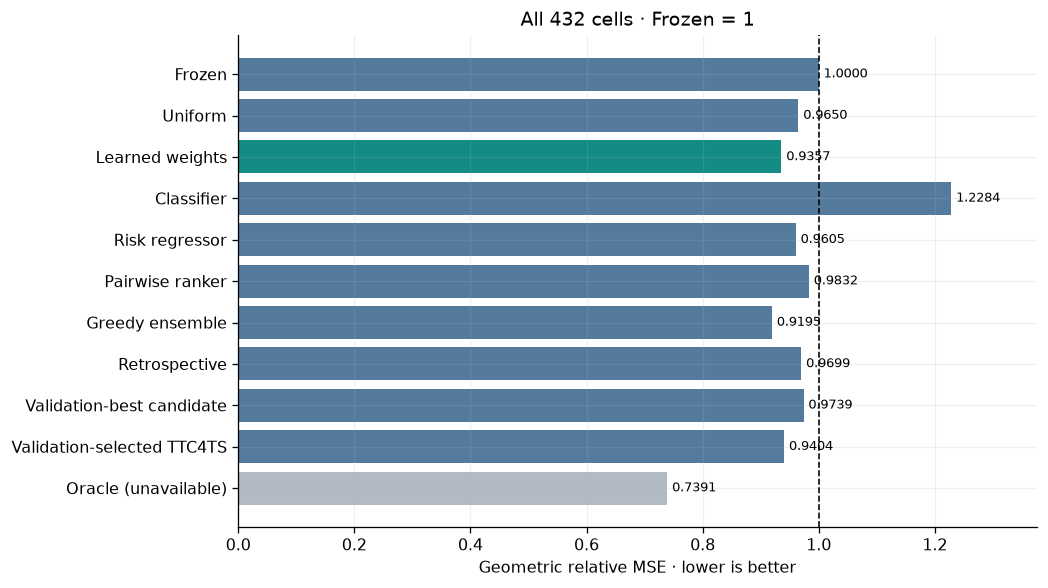

model,Chronos-2,Bolt-B,Bolt-S,Sundial,Timer,TimesFM
dataset,,,,,,
Appliances,0.89785,0.98677,0.96916,0.93993,0.95446,0.91772
BeijingWeather,0.80323,0.91343,0.89157,0.95519,0.97213,0.86060
ETTh1,0.88263,0.88941,0.90613,0.97834,0.97214,0.93835
ETTh2,0.94972,0.97044,0.98814,0.97185,0.97612,0.97422
ETTm1,0.88514,0.89271,0.88760,0.96348,0.97835,0.89724
ETTm2,0.95958,0.96252,0.97963,0.96282,0.96390,0.93093


In [3]:
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
colors = ['#138c85' if m=='weighted' else '#b2bac4' if m=='oracle' else '#547b9e' for m in table.method]
bars = ax.barh(table.method.map(METHOD_LABELS), table.relative_mse, color=colors)
ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
ax.axvline(1, color='black', ls='--', lw=1); ax.invert_yaxis()
ax.set_xlim(0, max(table.relative_mse)*1.12)
ax.set(xlabel='Geometric relative MSE · lower is better', title='All 432 cells · Frozen = 1')
plt.show()
by_dataset = summarize(headline[headline.method=='weighted'], ['dataset','model'])
display(by_dataset.pivot(index='dataset', columns='model', values='relative_mse').rename(columns=MODEL_LABELS))


The primary fixed Learned-weights rule and validation-selected TTC4TS are different estimators.
The Classifier is retained even when it degrades performance. Win counts are descriptive
counts across correlated tasks, not independent significance tests.

## Independent controls
The 17-method follow-up includes separately trained plain adapters and retrieval-transfer
controls. It uses the same 432-cell scope. Transfer controls are not in TTC4TS's candidate pool.


In [4]:
baselines = load_snapshot('baselines')
assert len(baselines) == 432*17
baseline_table = summarize(baselines).sort_values('relative_mse')
display(baseline_table)
print('Best observed independent-control MSE:', baseline_table.iloc[0]['method'])
print('Do not infer that every generator combination beats every component.')


,method,relative_mse,relative_mae,wins,cells
4,augmentations_weighted,0.93517,0.99043,395,432
2,ttc_weighted,0.93575,0.98785,420,432
5,retrieval_weighted,0.94296,0.98377,363,432
7,retrieval_aligned_identity,0.95304,0.98912,339,432
6,retrieval_aligned,0.95573,0.99168,312,432
1,ttc_uniform,0.96505,0.99739,406,432
12,plain_input,0.98097,1.01280,251,432
16,retrieval_raw,0.98138,1.01811,246,432
3,adapters_weighted,0.98513,1.00678,281,432
15,plain_selected,0.99089,1.02692,241,432


Best observed independent-control MSE: augmentations_weighted
Do not infer that every generator combination beats every component.


For underlying measured rows inspect `artifacts/main/all_metrics.csv.gz` and
`artifacts/baselines/all_metrics.csv`. The historical raw-prediction audit is included under
`artifacts/main/reports/`; reproducing its target-level checks requires newly generated or
separately archived raw arrays, not these summary CSVs alone.
